# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [7]:
file = Path(rf"configuration_PULSESTRUCT.toml")
uc = rp.UnitCell.from_toml(file)

O2 = uc.env.species.get("O2")

PULSES_NUMBER = uc.beam.tot_pulse()
print(PULSES_NUMBER)

2023-06-02 17:29:23,001::radiopyo::INFO::Loading config from TOML file: configuration_PULSESTRUCT.toml
2023-06-02 17:29:23,006::radiopyo::INFO::File is loaded
2023-06-02 17:29:23,007::radiopyo::INFO::Beam configuration detected in config file
2023-06-02 17:29:23,008::radiopyo::INFO::Beam PulsedBeam(dose_rate=0.030000000000000002, timer=Timer(period=0.2, on_time=2e-05, start_time=0.0), max_dose=0.030000000000000002, time_at_max_dose=0.8000200000000001, dose_per_pulse=0.006, peak_dose_rate=300.0) is setup
2023-06-02 17:29:23,009::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-06-02 17:29:23,009::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-06-02 17:29:23,010::radiopyo::INFO::CONFIG::38 K-reactions added
2023-06-02 17:29:23,011::radiopyo::INFO::CONFIG::1 Enzymatic reactions added
2023-06-02 17:29:23,012::radiopyo::INFO::CONFIG::6 Radiolytic reactions added
2023-06-02 17:29:23,012::radiopyo::INFO::CONFIG::19 Dynamical Species added.
2023-06-02 17:29:23,013::rad

**2) Run sim over the first pulse**

In [47]:
beam_def = uc.beam.as_dict()
beam_def.pop("dose_rate")
beam_def.pop("max_dose")
beam_def["n_pulse"] = PULSES_NUMBER
beam_def["dose_rate_peak"] = uc.beam.peak_dose_rate
print(beam_def)

rp.physics.beam.PulsedBeam.from_dict(beam_def)



{'period': 0.2, 'on_time': 2e-05, 'start_time': 0.0, 'n_pulse': 5.0, 'dose_rate_peak': 300.0}


PulsedBeam(dose_rate=0.030000000000000002, timer=Timer(period=0.2, on_time=2e-05, start_time=0.0), max_dose=0.030000000000000002, time_at_max_dose=0.8000200000000001, dose_per_pulse=0.006, peak_dose_rate=300.0)

In [22]:
res = uc.prepare_chunked_run([1e-9, uc.beam.timer.period],
                             max_step_size_on=0.01e-6,
                             max_step_size_off=1e-3).run()

2023-06-02 17:31:41,281::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 17:31:41,284::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 17:31:41,947::radiopyo::INFO::Simulation done!


**3) Run the next pulses**
* Reset beam start time  
* Copy final concentrations of previous sim  
* Reset the O2 concentration to its initial value (in µmol/L)  
* Run and append the simulation result to the previous result  

In [23]:
while res.time[-1] < uc.beam.time_at_max_dose:
    y0 = res.final_cc
    y0[O2.index] = O2.initial_cc()*1e6
    res +=  uc.prepare_chunked_run([res.time[-1], res.time[-1]+uc.beam.timer.period],
                                   max_step_size_on=0.01e-6,
                                   max_step_size_off=1e-3,
                                   y0=y0).run()

2023-06-02 17:31:43,757::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 17:31:43,759::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 17:31:44,294::radiopyo::INFO::Simulation done!
2023-06-02 17:31:44,296::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 17:31:44,298::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 17:31:44,829::radiopyo::INFO::Simulation done!
2023-06-02 17:31:44,830::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 17:31:44,833::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 17:31:45,365::radiopyo::INFO::Simulation done!
2023-06-02 17:31:45,369::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 17:31:45,372::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 17:31:45,889::radiopyo::INFO::Simulation done!


**Convert final result to pandas DataFrame**

In [11]:
df = res.to_pandas()

## Simulation Run LOOP

In [49]:
import itertools as it
all_res = pd.DataFrame()

In [51]:
ON_TIMES = [5e-6, 10e-6, 50e-6, 100e-6, 500e-6, 1e-3, 50e-3, 0.1]
PERIODS = [50e-6, 100e-6, 500e-6, 1e-3, 0.1, 1, 10, 30, 60]

for idx, (on_time, period) in enumerate(it.product(ON_TIMES, PERIODS)):
    if period <= on_time:
        continue
    beam_def["on_time"] = on_time
    beam_def["period"] = period
    uc.set_beam(rp.physics.beam.PulsedBeam.from_dict(beam_def))

    res = uc.prepare_chunked_run([1e-9, uc.beam.timer.period],
                                 max_step_size_on=0.01e-6,
                                 max_step_size_off=1e-3).run()
    while res.time[-1] < uc.beam.time_at_max_dose:
        y0 = res.final_cc
        y0[O2.index] = O2.initial_cc()*1e6
        res +=  uc.prepare_chunked_run([res.time[-1], res.time[-1]+uc.beam.timer.period],
                                       max_step_size_on=0.01e-6,
                                       max_step_size_off=1e-3,
                                       y0=y0).run()
    df = res.to_pandas()
    
    all_res.loc[:, idx] = np.empty(7)
    all_res.iloc[0,idx] = beam_def["on_time"]
    all_res.iloc[1,idx] = beam_def["period"]
    for pulse in range(int(PULSES_NUMBER)):
        all_res.iloc[2+pulse, idx] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)["ROO_r"]

2023-06-02 18:15:49,090::radiopyo::INFO::Setting new beam definition: PulsedBeam(dose_rate=30.0, timer=Timer(period=5e-05, on_time=5e-06, start_time=0.0), max_dose=0.007500000000000001, time_at_max_dose=0.00020500000000000002, dose_per_pulse=0.0015, peak_dose_rate=300.0), done!
2023-06-02 18:15:49,091::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 18:15:49,093::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 18:15:49,324::radiopyo::INFO::Simulation done!
2023-06-02 18:15:49,324::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 18:15:49,328::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 18:15:49,547::radiopyo::INFO::Simulation done!
2023-06-02 18:15:49,550::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 18:15:49,553::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

... (182 outputs left out)

2023-06-02 18:21:22,225::radiopyo::INFO::Simulation done!
2023-06-02 18:21:22,228::radiopyo::INFO::Simulation divided in 2 chunks
2023-06-02 18:21:22,230::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-06-02 18:21:23,442::radiopyo::INFO::Simulation done!


IndexError: iloc cannot enlarge its target object

In [53]:
all_res

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19
0,5.000000e-06,5.000000e-06,5.000000e-06,5.000000e-06,0.000005,0.000005,0.000005,0.000005,0.000005,1.000000e-05,1.000000e-05,1.000000e-05,1.000000e-05,0.000010,0.000010,0.000010,0.000010,0.000010,-1.0
1,5.000000e-05,1.000000e-04,5.000000e-04,1.000000e-03,0.100000,1.000000,10.000000,30.000000,60.000000,5.000000e-05,1.000000e-04,5.000000e-04,1.000000e-03,0.100000,1.000000,10.000000,30.000000,60.000000,0.0
2,8.819524e-10,3.434391e-09,7.446636e-08,9.991317e-07,4.168920,37.268099,157.123721,220.131166,243.359707,1.591551e-09,5.205230e-09,1.322935e-07,3.876844e-07,0.374305,7.059195,49.754442,86.152399,102.168987,1.0
3,2.907234e-09,6.506665e-09,3.403846e-07,1.065328e-05,4.329979,26.325966,42.345314,23.228541,7.586393,4.419089e-09,2.603513e-08,3.765254e-07,9.504864e-07,0.777208,6.686274,23.352927,15.905729,5.829778,2.0
4,7.773541e-09,1.472580e-08,4.920850e-07,1.335593e-05,4.133449,20.066510,20.662130,5.913128,0.628963,1.505684e-08,3.242900e-08,6.666579e-07,1.477622e-06,0.768350,6.024840,12.987785,4.343658,0.781113,3.0
5,1.335008e-08,2.520471e-08,5.725135e-07,1.360089e-05,3.957288,16.088063,11.699017,1.673265,0.054134,2.609228e-08,5.526382e-08,9.557058e-07,2.100579e-06,0.759055,5.460577,7.807498,1.361446,0.361394,4.0
6,1.442825e-08,6.129653e-08,5.999684e-07,1.367867e-05,3.771798,13.329440,7.083099,0.486451,0.004674,3.673902e-08,8.183849e-08,1.152862e-06,2.296464e-06,0.748034,4.972750,4.894379,0.522180,0.325523,5.0


## Results usage

**Integrate values per pulse**

In [12]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

### Plot

In [13]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1

#### Water-only Radiolytic produced species

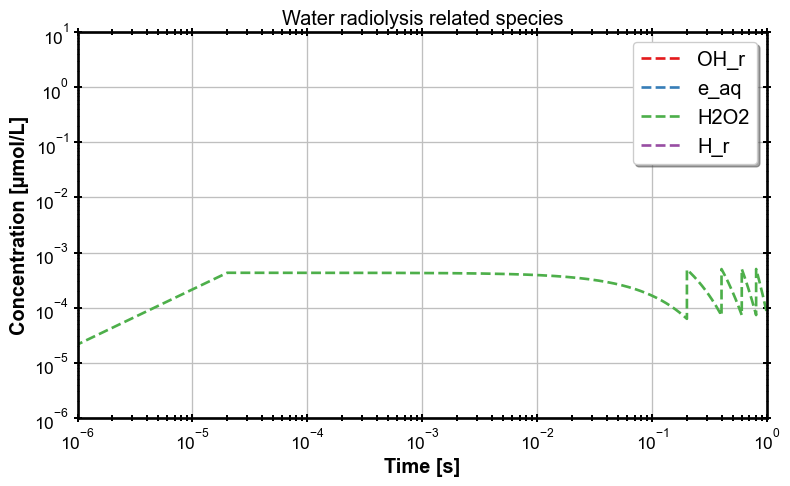

In [24]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]

with fig_man.open(f"Water radiolysis related species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=1e-6, top=10)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Water radiolysis related species")

#### Biology related species

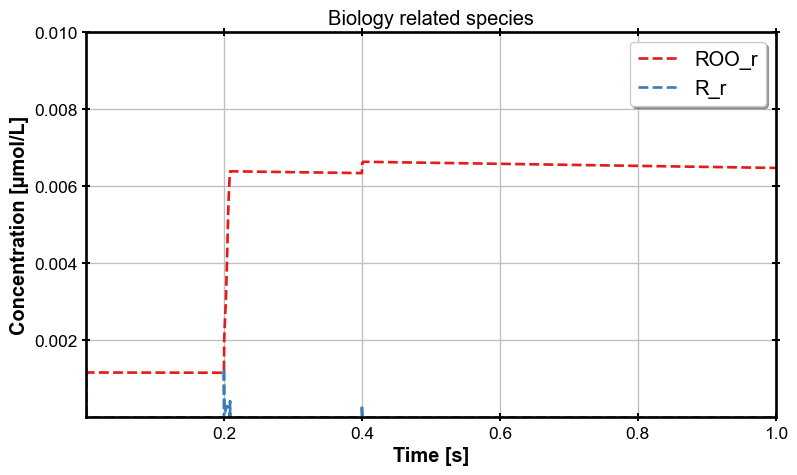

In [31]:
G_species = ["ROO_r", "R_r"]
with fig_man.open(f"Biology related species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=1e-6, top=1e-2)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

#### O2

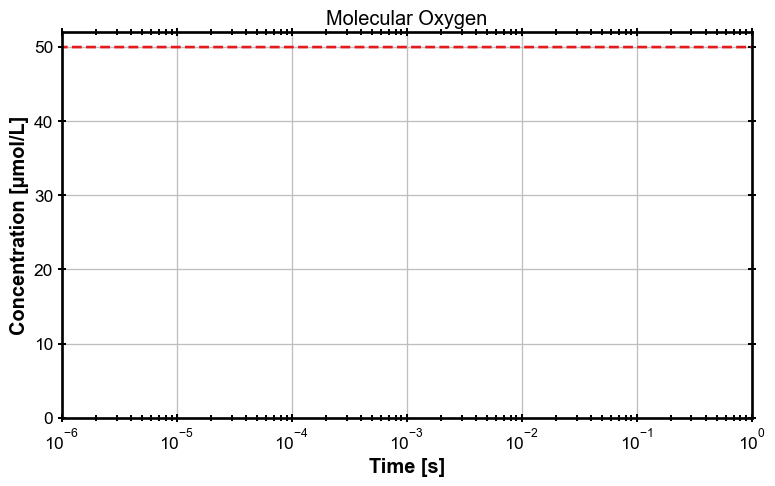

In [26]:
G_species = ["O2"]
with fig_man.open(f"Molecular Oxygen") as (fig, ax):
    
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=0, top=52)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.set_title("Molecular Oxygen")


## Compare Pulses

**Integrate values per pulse**

In [32]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

In [33]:
by_pulse

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,RH_r,R_r,ROO_r,ROH,RO,ROOH
0,0.0,0.0,0.000038,0.0,0.0,0.000002,0.0,0.0,0.000063,9.999233,0.0,0.0,0.0,0.000285,0.000001,0.000615,0.0,0.0,0.0
1,0.0,0.0,0.000044,0.0,0.0,0.000004,0.0,0.0,0.000127,9.999921,0.0,0.000039,0.0,0.00053,0.0,0.000683,0.0,0.0,0.0
2,0.0,0.0,0.000044,0.0,0.0,0.000006,0.0,0.0,0.00019,9.999363,0.0,0.000137,0.0,0.000775,0.0,0.000747,0.0,0.0,0.0
3,0.0,0.0,0.000045,0.0,0.0,0.000007,0.0,0.0,0.000253,9.999367,0.0,0.000272,0.0,0.001022,0.0,0.000829,0.0,0.0,0.0
4,0.0,0.0,0.000044,0.0,0.0,0.000009,0.0,0.0,0.000315,9.953993,0.0,0.000429,0.0,0.001263,0.0,0.000911,0.0,0.0,0.0


### ON time

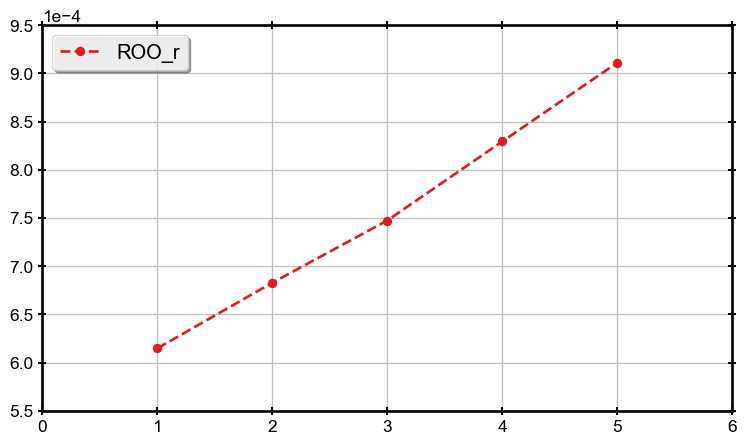

In [36]:
with fig_man.open(f"Pulse Integral") as (fig, ax):
    ax.plot(by_pulse.index+1, by_pulse["ROO_r"], label="ROO_r")
    ax.legend()

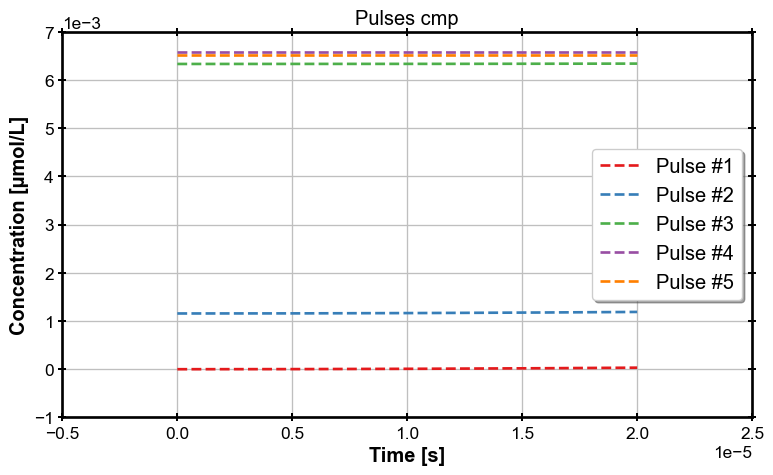

In [27]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period
        mask = (df.index>=start_pulse) & (df.index < start_pulse+uc.beam.timer.on_time)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,1])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")

### OFF Time

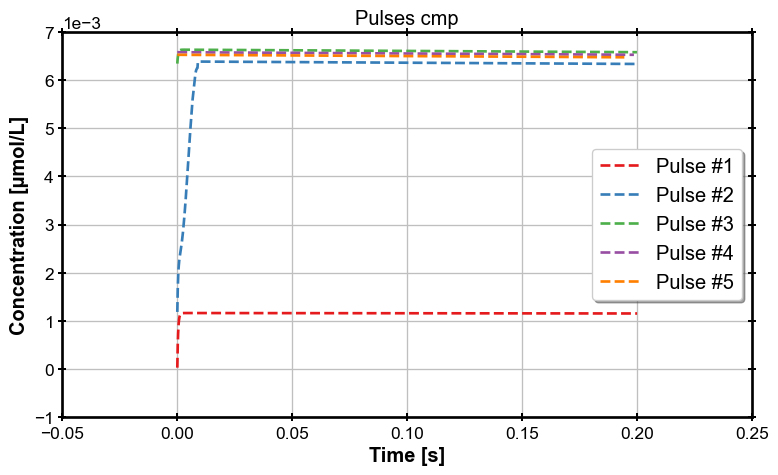

In [28]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period + uc.beam.timer.on_time
        mask = (df.index>=start_pulse) & (df.index < (pulse+1)*uc.beam.timer.period)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,0.12])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")